# TP3B · Simulador de RedBaires

Este notebook es el simulador de la segunda entrega. Lo armamos en Python con SimPy, en el mismo orden en que se haría un pase a mano: primero una publicación sola, después la cola de moderación con pocos ítems, después un día entero, y recién ahí el mes completo, el cálculo de N y el stress test.

Cada paso dice de qué parte del modelo conceptual y del modelo de datos de la entrega A sale, y qué bloque de AnyLogic haría lo mismo, porque es el lenguaje que usamos en clase. La tabla completa de equivalencias está en el `README.md` de esta carpeta.

Para correrlo hacen falta los dos CSV del campus en `datos/` (no se suben al repo) y las librerías de `parte-b/requirements.txt`.

In [1]:
import numpy as np, pandas as pd, simpy
import matplotlib.pyplot as plt
from scipy import stats

TIPOS = ["BROADCASTER", "CREATOR", "AGGREGATOR", "LURKER", "STANDARD"]
SENSIBLES = ("DISARM", "ORG-POL", "ORG-HLTH")   # temas con remoción más dura (supuesto de la parte A)
plt.rcParams["figure.figsize"] = (9, 3.2)

## Paso 1 · Los parámetros, desde los datos

Todo lo que el simulador necesita sale de la tabla diccionario de la entrega A. Lo volvemos a calcular desde `muestra_cascadas_REDBAIRES.csv` en vez de copiar los números, así cualquiera del grupo puede verificar de dónde sale cada uno. Limpiamos igual que en la parte A: sin eventos duplicados y sin las 14 cascadas cortadas en 500 eventos.

| Del modelo de datos | Cómo lo calculamos |
|---|---|
| hijos por evento Rᵢ, por tipo de cuenta | promedio de `reshare_count_from_actor` por tipo |
| decaimiento δ(g) | hijos medios en la generación g sobre los de la generación 1 |
| tipos del frente hijo | proporción de cada tipo entre los eventos que no son semilla |
| seguidores | la muestra empírica de cada tipo, para sortear con reposición |
| probabilidad de marca | `moderation_flag` medio por nocivo/legítimo y quintil de toxicidad |
| publicaciones por hora | semillas por hora del día ÷ 180 días × factor de escala |

El factor de escala no sale de los datos: lo calibramos en el paso 5.

In [2]:
def parametros(ruta="../datos/muestra_cascadas_REDBAIRES.csv", escala=53):
    d = pd.read_csv(ruta).drop_duplicates("event_id")
    d["tipo"] = d.account_type_code.str.upper()
    d["tipo_i"] = d.tipo.map({t: i for i, t in enumerate(TIPOS)})
    d["tema"] = d.topic_code.str.upper()
    d["nociva"] = d.tema.str.startswith("DISARM")
    d["coord"] = d.hashtag_cluster_ref.str.upper().str.endswith("C2")
    tam = d.groupby("cascade_id").size()
    d = d[~d.cascade_id.isin(tam[tam >= 500].index)]               # sin las cascadas cortadas

    P = {"escala": escala}
    P["R"] = d.groupby("tipo").reshare_count_from_actor.mean().reindex(TIPOS).to_numpy()
    hijos_g = d.groupby("cascade_depth").reshare_count_from_actor.mean()
    P["delta"] = (hijos_g / hijos_g.loc[1]).to_numpy()              # δ(g) para g = 0, 1, 2…
    P["m_coord"] = d[d.coord].reshare_count_from_actor.mean() / d[~d.coord].reshare_count_from_actor.mean()
    P["p_hijo"] = d[d.seed_flag == 0].tipo.value_counts(normalize=True).reindex(TIPOS).to_numpy()
    P["seguidores"] = [d[d.tipo == t].actor_follower_count.to_numpy() for t in TIPOS]
    P["verif"] = d.groupby("tipo").verified_flag.mean().reindex(TIPOS).to_numpy()
    P["cortes_tox"] = d.toxicity_index.quantile([.2, .4, .6, .8]).to_numpy()
    d["quintil"] = np.searchsorted(P["cortes_tox"], d.toxicity_index)
    P["p_marca"] = d.groupby(["nociva", "quintil"]).moderation_flag.mean().unstack().to_numpy()
    P["frac_nociva_ev"] = d.nociva.mean()

    sem = d[d.seed_flag == 1]
    P["semillas"] = sem[["tipo_i", "tema", "nociva", "coord", "toxicity_index"]].reset_index(drop=True)
    horas = pd.to_datetime(sem.forward_datetime, errors="coerce").dt.hour
    P["lam"] = horas.value_counts().reindex(range(24), fill_value=0).to_numpy() / 180 * escala / 60  # por minuto
    P["frac_coord"] = sem.coord.mean()
    return P, d

P, datos = parametros()
pd.DataFrame({"R": P["R"].round(2), "verificadas": P["verif"].round(2), "p_hijo": P["p_hijo"].round(3)}, index=TIPOS)

,R,verificadas,p_hijo
BROADCASTER,4.44,1.00,0.029
CREATOR,3.53,0.75,0.054
AGGREGATOR,0.58,0.05,0.224
LURKER,0.59,0.05,0.196
STANDARD,0.59,0.06,0.497


Los R dan lo mismo que en la parte A: 4,44 para BROADCASTER, 3,52 para CREATOR y alrededor de 0,59 para los otros tres. El decaimiento arranca en 2,33 en la semilla y baja a 0,37 en la generación 11. Con la escala de 53, que calibramos en el paso 5, llegan unas 1.470 publicaciones por día.

In [3]:
print("δ(g):", P["delta"][:12].round(2))
print("probabilidad de marca (filas: legítima, nociva; columnas: quintil de toxicidad)\n", P["p_marca"].round(3))
print("publicaciones por día:", round(P["lam"].sum() * 60))

δ(g): [2.33 1.   0.84 0.77 0.67 0.64 0.62 0.55 0.49 0.44 0.39 0.37]
probabilidad de marca (filas: legítima, nociva; columnas: quintil de toxicidad)
 [[0.091 0.128 0.173 0.211 0.26 ]
 [0.204 0.249 0.302 0.343 0.4  ]]
publicaciones por día: 1468


## Paso 2 · Una publicación sola, a mano

La entidad es la publicación, como decidimos en la parte A. Nace en el evento **publicar**, que en AnyLogic sería un `Source`, y sus atributos (tema, toxicidad, coordinada, frente de reenvíos, reenvíos acumulados, fracción removida) son los campos de un *agent type*. Acá es un diccionario.

En cada vuelta del lazo pasa el evento **saltar de generación**, igual que en la figura 2 de la parte A:

1. se expone el frente: cada reenvío suma 0,15 × los seguidores de quien reenvía;
2. Centinela marca *k* reenvíos del frente, y si *k* > 0 nace un ítem de moderación (un `SelectOutput` que manda una copia a la otra rama);
3. se sortea el frente siguiente con **un solo** sorteo de Poisson de media Λ = Σ nᵢ Rᵢ δ(g) (1 − r)(1 − f), en vez de uno por reenvío;
4. la publicación espera la demora entre generaciones, gamma de forma 0,55 y escala 128 min (un `Delay`).

Cuando el frente queda vacío, la publicación muere (`Sink`). Las palancas que todavía no usamos (fricción, degradación, clasificador nuevo) ya están en la fórmula, apagadas.

Cada publicación usa su propio generador de números aleatorios, sembrado con su número. Así dos escenarios ven exactamente las mismas publicaciones, y la diferencia entre ellos es de la palanca y no del azar. Es lo que en la parte A llamamos «los mismos números aleatorios».

In [4]:
from scipy.special import gammaincinv

def poisson_inv(u, lam):                     # el menor k con F(k) ≥ u: el mismo u da el mismo k o uno vecino
    if lam > 300:
        return int(max(0, round(stats.norm.ppf(u, lam, np.sqrt(lam)))))
    k, p = 0, np.exp(-lam)
    c = p
    while u > c:
        k += 1; p *= lam / k; c += p
    return k

def binom_inv(u, n, q):
    k, p = 0, (1 - q) ** n
    c = p
    while u > c and k < n:
        k += 1; p *= (n - k + 1) / k * q / (1 - q); c += p
    return k

VD_HOY = dict(c=1, umbral=None, reduccion=0.0, degradar=False, d=0.5, clasificador=None, volumen=1.0)

class RedBaires:
    def __init__(self, P, VD, semilla=1):
        self.P, self.VD, self.s = P, {**VD_HOY, **VD}, semilla
        self.env = simpy.Environment()
        self.moderadores = simpy.Resource(self.env, capacity=self.VD["c"])     # ResourcePool
        self.rng_llegadas = np.random.default_rng([semilla, 0])
        self.VR = dict(nocivas=0.0, legitimas=0.0, friccion_legit=0.0, items=0, buenas_bajadas=0)
        self.VE = {"cola": [(0, 0)], "ocupados": [(0, 0)], "vivas": [(0, 0)]}   # se escriben sólo en los eventos
        self.cola = self.vivas = 0
        self.latencias, self.tamanos, self.traza = [], [], None
        self.con_moderacion = True

    def anotar(self, ve, valor):
        self.VE[ve].append((self.env.now, valor))

In [5]:
def p_marca(self, pub):
    if self.VD["clasificador"] is not None:                      # clasificador nuevo: (precisión, recall)
        prec, rec = self.VD["clasificador"]
        pi = self.P["frac_nociva_ev"]
        return rec if pub["nociva"] else rec * pi * (1 - prec) / (prec * (1 - pi))
    q = int(np.searchsorted(self.P["cortes_tox"], pub["tox"]))
    return self.P["p_marca"][int(pub["nociva"]), q]

def publicar(self, i):
    P, VD = self.P, self.VD
    rng = np.random.default_rng([self.s, 2, i])                  # atributos de la publicación
    s = P["semillas"].iloc[rng.integers(len(P["semillas"]))]
    pub = dict(id=i, nociva=bool(s.nociva), tox=s.toxicity_index, coord=bool(s.coord),
               sensible=s.tema.startswith(SENSIBLES), f=0.0, acum=0)
    recall_det, fp_det = 0.47, 0.47 * P["frac_coord"] * (1 - 0.21) / (0.21 * (1 - P["frac_coord"]))
    pub["detectada"] = VD["degradar"] and rng.random() < (recall_det if pub["coord"] else fp_det)
    frente = np.zeros(5); frente[s.tipo_i] = 1
    g, total = 0, 0
    self.vivas += 1; self.anotar("vivas", self.vivas)
    while frente.sum() > 0:
        rg = np.random.default_rng([self.s, 3, i, g])            # los mismos sorteos en cada generación
        u_hijos, u_marca, u_demora = rg.random(3)
        n = int(frente.sum()); total += n
        alcance = (1 - VD["d"]) if pub["detectada"] else 1.0
        seguidores = sum(P["seguidores"][t][rg.integers(len(P["seguidores"][t]), size=int(frente[t]))].sum()
                         for t in range(5) if frente[t])
        impresiones = 0.15 * seguidores * alcance                       # 1. exponer
        self.VR["nocivas" if pub["nociva"] else "legitimas"] += impresiones
        k = binom_inv(u_marca, n, self.p_marca(pub))         # 2. marcar
        if k and self.con_moderacion:
            v = (frente * P["verif"]).sum() / n
            self.env.process(self.moderar(pub, k, n, v, g))
        pub["acum"] += n                                                # 3. sortear el frente siguiente
        friccion = VD["umbral"] is not None and pub["acum"] >= VD["umbral"]
        if friccion and not pub["nociva"]:
            self.VR["friccion_legit"] += 0.15 * impresiones
        lam = ((frente * P["R"]).sum() * P["delta"][min(g, len(P["delta"]) - 1)]
               * (P["m_coord"] if pub["coord"] else 1) * (1 - VD["reduccion"] if friccion else 1)
               * (1 - pub["f"]) * alcance)
        hijos = poisson_inv(u_hijos, lam) if lam > 0 else 0
        if self.traza is not None:
            self.traza.append(dict(t=round(self.env.now), g=g, frente=frente.astype(int).tolist(), n=n,
                                   impresiones=round(impresiones), k=k, Λ=round(lam, 2), hijos=hijos))
        frente = np.bincount(rg.choice(5, size=hijos, p=P["p_hijo"]), minlength=5).astype(float)
        if hijos:
            yield self.env.timeout(gammaincinv(0.55, u_demora) * 128)   # 4. demora entre generaciones
        g += 1
    self.vivas -= 1; self.anotar("vivas", self.vivas)
    self.tamanos.append(total)

RedBaires.p_marca, RedBaires.publicar = p_marca, publicar

Seguimos una sola publicación generación por generación. Buscamos una semilla que arranque en una cuenta BROADCASTER para que la cascada tenga algo para mirar; la columna `frente` cuenta los reenvíos vivos de cada tipo, en el orden BROADCASTER, CREATOR, AGGREGATOR, LURKER, STANDARD.

In [6]:
sim = RedBaires(P, {}, semilla=3)
sim.traza, sim.con_moderacion = [], False             # la cola todavía no existe
i = next(i for i in range(500) if P["semillas"].iloc[np.random.default_rng([3, 2, i]).integers(len(P["semillas"]))].tipo_i == 0)
sim.env.process(sim.publicar(i))
sim.env.run()
pd.DataFrame(sim.traza)

,t,g,frente,n,impresiones,k,Λ,hijos
0,0,0,"[1, 0, 0, 0, 0]",1,32756,0,10.37,8
1,226,1,"[0, 1, 1, 1, 5]",8,20084,3,7.65,8
2,265,2,"[1, 0, 3, 0, 4]",8,81058,2,7.21,7
3,265,3,"[0, 0, 2, 0, 5]",7,7902,2,3.18,3
4,281,4,"[0, 0, 1, 0, 2]",3,175,0,1.19,0


En la primera fila está la semilla sola, con un Λ alto porque es un BROADCASTER (R = 4,44) en la generación 0, donde δ vale 2,33. Las marcas *k* de cada fila son las que después van a la cola de moderación; en este paso todavía no hay nadie que las revise, así que la fracción removida *f* queda en cero y la cascada se apaga sola, porque el proceso es subcrítico.

## Paso 3 · La cola de moderación, a mano

El ítem de moderación es la segunda entidad. Nace cuando Centinela marca *k* reenvíos y hace este recorrido, que en AnyLogic serían cuatro bloques:

`Delay` de 90 minutos (el piso de la latencia) → `Queue` FIFO → `Service` con un `ResourcePool` de *c* moderadores → `Sink`.

El tiempo de revisión es Erlang de *k* fases de 20 segundos, como en la tabla diccionario. Al terminar se sortea cuántos de los *k* se remueven, con probabilidad toxicidad × 1,5 en temas sensibles y la mitad para las cuentas verificadas, y esa fracción se descuenta del frente de la publicación: es la flecha punteada roja del IDEF0.

Las variables de estado (largo de la cola, moderadores ocupados) se anotan **en el momento en que cambian**: cuando un ítem entra a la cola, cuando empieza a revisarse y cuando termina. No las muestreamos cada tanto, que es lo que pide la grilla.

In [7]:
def moderar(self, pub, k, n, v, g=0):
    rm = np.random.default_rng([self.s, 4, pub.get("id", -1), g])   # el mismo ítem sortea lo mismo en todo escenario
    marca = self.env.now
    yield self.env.timeout(90)                                        # Delay: piso de 90 min
    self.cola += 1; self.anotar("cola", self.cola)                     # entra a la Queue
    with self.moderadores.request() as pedido:                         # Seize
        yield pedido
        self.cola -= 1; self.anotar("cola", self.cola)
        self.anotar("ocupados", self.moderadores.count)
        yield self.env.timeout(rm.gamma(k, 20 / 60))                    # Erlang(k, 20 s), en minutos
    self.anotar("ocupados", self.moderadores.count)                    # Release
    self.latencias.append(self.env.now - marca)
    p = min(1.0, pub["tox"] * (1.5 if pub["sensible"] else 1) * (1 - 0.5 * v))
    removidos = rm.binomial(k, p)
    pub["f"] = min(1.0, pub["f"] + removidos / n)
    self.VR["items"] += k
    if not pub["nociva"]:
        self.VR["buenas_bajadas"] += removidos

RedBaires.moderar = moderar

Probamos la cola sola, con seis ítems marcados en minutos que elegimos nosotros y un moderador, igual que la tabla de la clase 07 (slide 21). Los tres primeros llegan juntos, así que el segundo y el tercero esperan.

In [8]:
sim = RedBaires(P, dict(c=1), semilla=1)
filas = []
def item_de_prueba(t, k):
    yield sim.env.timeout(t)
    pub = dict(id=t, tox=0.5, sensible=False, nociva=True, f=0.0)
    inicio = sim.env.now
    yield sim.env.process(sim.moderar(pub, k, n=10, v=0.0))
    filas.append(dict(marcado=t, k=k, llega_a_la_bandeja=t + 90, sale=round(sim.env.now, 1),
                      latencia=round(sim.env.now - t, 1)))
for t, k in [(0, 6), (0, 3), (0, 4), (5, 2), (30, 5), (31, 1)]:
    sim.env.process(item_de_prueba(t, k))
sim.env.run()
pd.DataFrame(filas)

,marcado,k,llega_a_la_bandeja,sale,latencia
0,0,6,90,91.7,91.7
1,0,3,90,92.5,92.5
2,0,4,90,93.6,93.6
3,5,2,95,96.1,91.1
4,30,5,120,120.7,90.7
5,31,1,121,121.3,90.3


Ningún ítem tiene latencia menor a 90 minutos, y los que llegan juntos se ordenan uno detrás de otro: el moderador tarda unos 2 minutos con un ítem de *k* = 6 (6 fases de 20 segundos). Es la lógica de la fila, controlada a mano antes de meterla en el modelo grande.

## Paso 4 · Un día entero

Ahora juntamos las dos ramas. El evento exógeno **publicar** es un `Source` con tasa por hora del día: el tiempo entre publicaciones es exponencial con la tasa de esa hora, como en la parte A (prueba de Kolmogorov-Smirnov, D = 0,014).

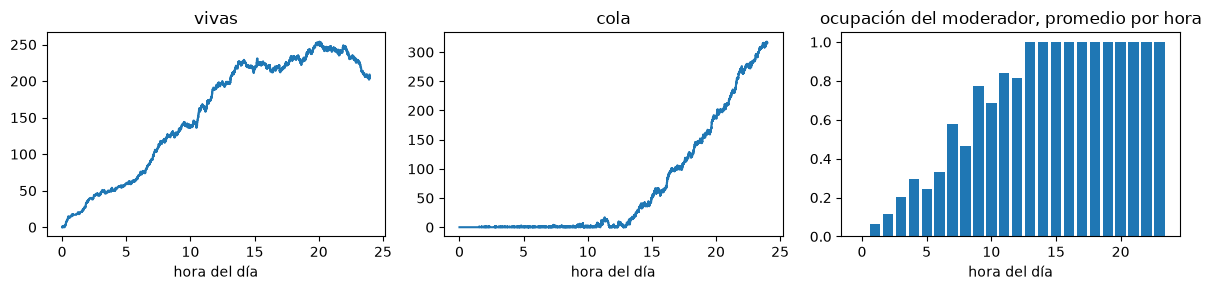

In [9]:
def llegadas(self):
    i = 0
    while True:
        h = int(self.env.now // 60) % 24
        yield self.env.timeout(self.rng_llegadas.exponential(1 / (self.P["lam"][h] * self.VD["volumen"])))
        self.env.process(self.publicar(i))
        i += 1

def correr(self, dias, calentamiento=0):
    self.env.process(self.llegadas())
    if calentamiento:                                    # se descarta el transitorio (clase 08)
        self.env.run(until=calentamiento * 1440)
        self.VR = {k: 0 * v for k, v in self.VR.items()}
        self.latencias, self.tamanos = [], []
    self.env.run(until=(calentamiento + dias) * 1440)
    return self

RedBaires.llegadas, RedBaires.correr = llegadas, correr

def escalones(ax, serie, etiqueta):
    t, v = zip(*serie)
    ax.step(np.array(t) / 60, v, where="post", label=etiqueta)

def promedio_por_hora(serie, horas):
    t, v = map(np.array, zip(*serie))
    out = []
    for h in range(horas):
        a, b = h * 60, (h + 1) * 60
        tt = np.clip(np.append(t, b), a, b)
        out.append(np.sum(np.diff(tt) * v) / 60)
    return out

dia = RedBaires(P, dict(c=1), semilla=1).correr(dias=1)
fig, ejes = plt.subplots(1, 3, figsize=(12, 3))
for ax, ve in zip(ejes[:2], ["vivas", "cola"]):
    escalones(ax, dia.VE[ve], ve); ax.set_title(ve); ax.set_xlabel("hora del día")
ejes[2].bar(range(24), promedio_por_hora(dia.VE["ocupados"], 24))
ejes[2].set_title("ocupación del moderador, promedio por hora"); ejes[2].set_xlabel("hora del día")
plt.tight_layout()

Las tres variables de estado de la parte A, a lo largo de un día con el moderador de hoy. Las publicaciones vivas siguen la forma de las llegadas por hora. El día arranca sin nada en el sistema, que es el transitorio: por eso en las corridas largas descartamos los primeros dos días. Durante la mañana el moderador alcanza y la cola casi no existe. Desde el mediodía las llegadas pasan su capacidad, el moderador queda ocupado todo el tiempo y la cola crece hasta la noche.

Esto es justo la limitación que declaramos en la parte A: en los datos la latencia no sube en la hora pico, y en una fila sí. Lo vamos a ver de nuevo en el stress test.

## Paso 5 · Validación y calibración de la escala

Antes de usar el modelo lo comparamos con los datos, que es el cuadro 1 del plan de la parte A. El tamaño de las cascadas y la fracción de impresiones nocivas no dependen de la escala. La latencia sí, y con ella calibramos.

En la parte A estimamos la escala en unos 50 con una M/M/1. En la simulación el tiempo de revisión es Erlang y no exponencial, y con 50 la mediana de la latencia da unos 105 minutos. Probamos escalas de 50 a 54 con el horizonte que vamos a usar, un mes, dos días de calentamiento descartados y dos semillas. Primero la habíamos calibrado con corridas de cinco días y había salido 54, pero en un mes esa escala hace crecer la cola sin parar.

In [10]:
def mediana_latencia(escala, semillas=(1, 2)):
    Pe, _ = parametros(escala=escala)
    return [round(np.median(RedBaires(Pe, dict(c=1), semilla=s).correr(dias=30, calentamiento=2).latencias))
            for s in semillas]

pd.DataFrame({"escala": e, "latencia mediana, semilla 1 y 2 (min)": mediana_latencia(e)} for e in (50, 52, 53, 54))

,escala,"latencia mediana, semilla 1 y 2 (min)"
0,50,"[104, 111]"
1,52,"[115, 131]"
2,53,"[130, 135]"
3,54,"[581, 169]"


Con 54 la cola de un mes no se estabiliza: en una de las dos semillas la latencia mediana pasa los 500 minutos. Con 53 queda en 130 y 135, cerca de los 139 observados, y con 52 baja a 115. Es la fragilidad que anticipamos en la evaluación a priori: con un moderador casi al 100 % de ocupación, un 2 % más de volumen cambia todo. Nos quedamos con 53. Con esa escala comparamos el resto:

In [11]:
v = RedBaires(P, dict(c=1), semilla=5).correr(dias=7, calentamiento=2)
tam_obs = datos.groupby("cascade_id").size()
lat_obs = datos.loc[datos.moderation_flag == 1, "moderation_latency_min"]
lat_obs = lat_obs[(lat_obs > 0) & (lat_obs < 1440)]
imp = datos.groupby("nociva").impressions.sum()
pd.DataFrame({
    "observado": [tam_obs.mean(), np.percentile(tam_obs, 90), np.percentile(tam_obs, 99), imp[True] / imp.sum(), lat_obs.median()],
    "simulado": [np.mean(v.tamanos), np.percentile(v.tamanos, 90), np.percentile(v.tamanos, 99),
                 v.VR["nocivas"] / (v.VR["nocivas"] + v.VR["legitimas"]), np.median(v.latencias)],
}, index=["tamaño medio de la cascada", "tamaño p90", "tamaño p99", "fracción de impresiones nocivas",
          "latencia mediana (min)"]).round(2)

,observado,simulado
tamaño medio de la cascada,11.84,12.33
tamaño p90,28.50,34.00
tamaño p99,151.30,69.00
fracción de impresiones nocivas,0.41,0.41
latencia mediana (min),138.70,134.96


La latencia y la fracción nociva dan como en los datos, y el tamaño medio y el p90 de las cascadas también. El p99, en cambio, da la mitad del observado: el modelo genera menos cascadas enormes que las reales. La parte A ya lo había previsto: «si el modelo base queda por debajo del tamaño observado, se recalibran los R». Lo dejamos para revisar en grupo, porque son justo las cascadas que más daño hacen.

## Paso 6 · Un mes en las condiciones iniciales

Las condiciones iniciales son la situación de hoy: un moderador, sin fricción, sin degradación y con el Centinela actual. Corremos un mes (30 días), después de descartar dos días de calentamiento, y miramos las dos variables de referencia de la parte A.

In [12]:
mes = RedBaires(P, VD_HOY, semilla=11).correr(dias=30, calentamiento=2)
pd.Series({"impresiones nocivas servidas en el mes": f'{mes.VR["nocivas"]:.3e}',
           "impresiones legítimas servidas en el mes": f'{mes.VR["legitimas"]:.3e}',
           "ítems revisados": mes.VR["items"], "publicaciones buenas bajadas": mes.VR["buenas_bajadas"],
           "latencia mediana (min)": round(np.median(mes.latencias))})

impresiones nocivas servidas en el mes      9.487e+08
impresiones legítimas servidas en el mes    1.482e+09
ítems revisados                                120922
publicaciones buenas bajadas                    21325
latencia mediana (min)                            130
dtype: object

La segunda VR, las impresiones legítimas **perdidas**, no se puede leer de una sola corrida: es la diferencia contra el escenario base con los mismos números aleatorios, más el 15 % de las impresiones legítimas que cruzan el umbral de fricción. En el escenario base vale cero por definición. La calculamos con esta función, que usamos desde el paso 7:

In [13]:
def legitimas_perdidas(base, escenario):
    return (base.VR["legitimas"] - escenario.VR["legitimas"]) + escenario.VR["friccion_legit"]

## Paso 7 · Cuántas réplicas hacen falta (N)

Una réplica es un mes de operación. Para fijar el error admitido corregimos lo que habíamos escrito en la parte A, donde lo pusimos como el 5 % de la media del costo: la cátedra pide un error en valor absoluto (clase 02), y un porcentaje de un valor que todavía no conocemos no dice nada sobre la decisión. Lo fijamos desde la decisión más chica que hay que poder distinguir, que es sumar un moderador: cuesta 15.840 USD por mes, así que queremos que el intervalo no tenga más de la mitad de eso de semiamplitud, ±7.920 USD. Pasado a impresiones nocivas, con 0,0059 USD cada una, son ±1,34 millones de impresiones por mes.

Como comparamos escenarios con los mismos números aleatorios, lo que tiene que quedar dentro de ese error es la **diferencia** entre un escenario y el base, no cada uno por separado. Hacemos un piloto de N₀ = 6 meses con 1 y con 2 moderadores, y aplicamos la fórmula de la clase 02 a la diferencia:

N ≥ (s₀ · t / ε)²

In [14]:
N0, EPS = 6, 7920 / 0.0059
piloto, bases = [], []                     # bases: las corridas de hoy, para el resultado en condiciones iniciales
for s in range(N0):
    base = RedBaires(P, dict(c=1), semilla=100 + s).correr(dias=30, calentamiento=2)
    dos = RedBaires(P, dict(c=2), semilla=100 + s).correr(dias=30, calentamiento=2)
    bases.append(base)
    piloto.append(dict(nocivas_c1=base.VR["nocivas"], nocivas_c2=dos.VR["nocivas"],
                       evitadas=base.VR["nocivas"] - dos.VR["nocivas"], perdidas=legitimas_perdidas(base, dos)))
piloto = pd.DataFrame(piloto)
s0, t = piloto.evitadas.std(ddof=1), stats.t.ppf(0.975, N0 - 1)
N = int(np.ceil((s0 * t / EPS) ** 2))
print(f"desvío de la diferencia: {s0:.3e}   t(0,025; {N0-1}) = {t:.3f}   N ≥ {N}")
print(f"desvío de un escenario solo: {piloto.nocivas_c1.std(ddof=1):.3e}")

desvío de la diferencia: 8.055e+06   t(0,025; 5) = 2.571   N ≥ 238
desvío de un escenario solo: 2.088e+07


El desvío de la diferencia es menos de la mitad del de un escenario solo, porque las cascadas enormes aparecen igual en los dos escenarios y se cancelan al restar. Aun así, con ±7.920 USD de error hacen falta del orden de 240 meses por escenario, unas dos horas de cómputo cada uno. Para esta entrega nos quedamos con N = 238 meses por escenario, unos 7.140 días simulados. Si en la parte C el tiempo de cómputo no alcanza para todos los escenarios, la alternativa es relajar el error a un moderador entero, ±15.840 USD, con lo que N baja a la cuarta parte.

Con las seis réplicas del piloto ya podemos mostrar el primer resultado con su intervalo de confianza: lo que evita el segundo moderador.

In [15]:
def ic(x, conf=0.95):
    x = np.asarray(x, float)
    hw = stats.t.ppf(0.5 + conf / 2, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x))
    return x.mean(), hw

for col in ["evitadas", "perdidas"]:
    m, hw = ic(piloto[col])
    print(f"{col:>9}: {m:.3e} ± {hw:.2e} impresiones por mes")

 evitadas: 2.822e+07 ± 8.45e+06 impresiones por mes
 perdidas: 1.644e+07 ± 4.49e+06 impresiones por mes


Con las mismas seis réplicas del piloto calculamos el resultado en las condiciones iniciales, que es lo que pide la grilla: un moderador, sin fricción, sin degradación y con el Centinela de hoy. Cada fila es la media de los seis meses con su intervalo de confianza del 95 %, con la t de Student de 5 grados de libertad. El costo del mes es el de la parte A con lo que sale de la corrida (0,0059 USD por impresión nociva, 1,50 por publicación buena bajada y 0,12 por ítem revisado) más la nómina de un moderador; las impresiones legítimas perdidas valen cero porque este es el escenario contra el que se miden.

La ocupación y el largo de la cola son promedios en el tiempo de las variables de estado que anotamos en cada evento, sin los dos días de calentamiento.

In [16]:
def promedio_temporal(serie, t_ini, t_fin):              # promedio de una VE en escalones, pesado por el tiempo que duró cada valor
    t, v = map(np.array, zip(*serie))
    t = np.clip(np.append(t, t_fin), t_ini, t_fin)
    return np.sum(np.diff(t) * v) / (t_fin - t_ini)

def costo_mes(r, nomina=15840):                             # criterio de decisión de la parte A, sin las legítimas perdidas
    return 0.0059 * r.VR["nocivas"] + 1.50 * r.VR["buenas_bajadas"] + 0.12 * r.VR["items"] + nomina * r.VD["c"]

inicial = pd.DataFrame({
    "impresiones nocivas servidas (millones)": [b.VR["nocivas"] / 1e6 for b in bases],
    "impresiones legítimas servidas (millones)": [b.VR["legitimas"] / 1e6 for b in bases],
    "publicaciones buenas bajadas": [b.VR["buenas_bajadas"] for b in bases],
    "ítems revisados": [b.VR["items"] for b in bases],
    "latencia mediana (min)": [np.median(b.latencias) for b in bases],
    "ocupación del moderador": [promedio_temporal(b.VE["ocupados"], 2 * 1440, b.env.now) / b.VD["c"] for b in bases],
    "ítems en la cola, promedio": [promedio_temporal(b.VE["cola"], 2 * 1440, b.env.now) for b in bases],
    "costo del mes (miles de USD)": [costo_mes(b) / 1e3 for b in bases],
})
pd.DataFrame([ic(inicial[c]) for c in inicial], index=inicial.columns, columns=["media", "± IC 95 %"]).round(3)

,media,± IC 95 %
impresiones nocivas servidas (millones),958.904,21.909
impresiones legítimas servidas (millones),1498.158,41.192
publicaciones buenas bajadas,21478.500,502.502
ítems revisados,121610.500,2194.757
latencia mediana (min),134.745,18.832
ocupación del moderador,0.936,0.018
"ítems en la cola, promedio",93.999,39.978
costo del mes (miles de USD),5720.186,129.581


## Paso 8 · Stress test

La grilla pide variar las VD para ver que el simulador responde como esperamos y que el consumo queda acotado. Corremos una semana por escenario, siempre con la misma semilla.

In [17]:
escenarios = {
    "hoy (c=1)": dict(c=1), "c=2": dict(c=2), "c=4": dict(c=4),
    "volumen +5 %, c=1": dict(c=1, volumen=1.05), "volumen +5 %, c=2": dict(c=2, volumen=1.05),
    "fricción u=5, r=0,3": dict(umbral=5, reduccion=0.3), "degradación sí": dict(degradar=True),
    "clasificador 0,85/0,75": dict(clasificador=(0.85, 0.75)),
}
corridas = {nombre: RedBaires(P, vd, semilla=21).correr(dias=7, calentamiento=2) for nombre, vd in escenarios.items()}
base = corridas["hoy (c=1)"]
pd.DataFrame({nombre: {"nocivas (millones)": r.VR["nocivas"] / 1e6,
                       "legítimas perdidas (millones)": legitimas_perdidas(base, r) / 1e6,
                       "latencia mediana": np.median(r.latencias), "cola máxima": max(v for _, v in r.VE["cola"]),
                       "vivas máximo": max(v for _, v in r.VE["vivas"])}
              for nombre, r in corridas.items()}).T.round(1)

,nocivas (millones),legítimas perdidas (millones),latencia mediana,cola máxima,vivas máximo
hoy (c=1),218.1,0.0,114.4,306.0,271.0
c=2,212.2,3.7,90.5,16.0,261.0
c=4,212.1,3.7,90.4,6.0,261.0
"volumen +5 %, c=1",231.8,-21.4,147.6,327.0,294.0
"volumen +5 %, c=2",224.1,-15.0,90.6,19.0,292.0
"fricción u=5, r=0,3",171.3,108.4,91.5,39.0,228.0
degradación sí,175.9,61.7,93.4,134.0,229.0
"clasificador 0,85/0,75",241.0,-11.9,2638.8,9026.0,293.0


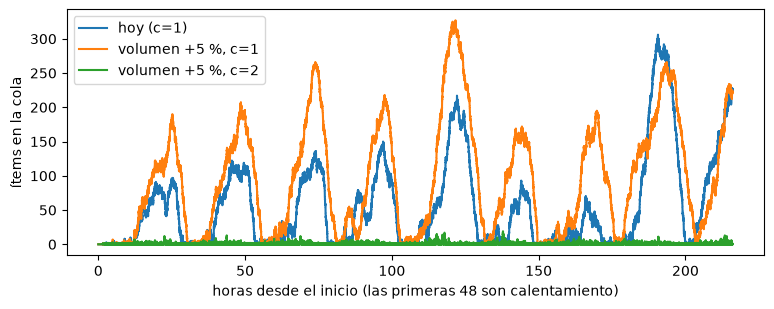

In [18]:
fig, ax = plt.subplots()
for nombre in ["hoy (c=1)", "volumen +5 %, c=1", "volumen +5 %, c=2"]:
    escalones(ax, corridas[nombre].VE["cola"], nombre)
ax.set_xlabel("horas desde el inicio (las primeras 48 son calentamiento)"); ax.set_ylabel("ítems en la cola"); ax.legend()

Con un moderador la cola se arma todas las tardes y se vacía de noche, y con 5 % más de volumen los picos son más altos pero también se vacía. La evaluación a priori de la parte A decía que con 5 % más la cola crecería sin límite. Lo que la corrige es que la tasa cambia con la hora: de noche llegan muchas menos publicaciones y el moderador se pone al día. Con dos moderadores no hay cola en ningún momento. Las publicaciones vivas quedan acotadas en todos los escenarios, que era la condición del área de Simulación.

Dos cosas de la tabla para mirar con cuidado. En los escenarios de volumen la columna de legítimas perdidas no tiene sentido, porque cambian las publicaciones que llegan y no hay contra qué comparar. Y el clasificador nuevo, con un solo moderador, da **más** impresiones nocivas que hoy: marca el doble de ítems, la cola explota (más de 9.000 ítems, latencia de casi dos días) y las remociones llegan cuando la cascada ya terminó. Un clasificador mejor sin más moderadores empeora las cosas, y eso hay que contarlo en la parte C.

## Paso 9 · Controles de debugging

Dejamos escritos los controles que corremos después de cada cambio. Si alguno falla, hay un error en el simulador:

1. ninguna latencia puede ser menor a los 90 minutos del piso;
2. la ley de Little en la cola: el largo promedio de la cola tiene que dar la tasa de llegada a la bandeja por la espera promedio en la cola (clase 07);
3. la ocupación medida de los moderadores tiene que dar cerca de λ · E[servicio] / c, que es la cuenta del balanceo previo.

In [19]:
r = corridas["c=2"]
assert min(r.latencias) >= 90, "latencia menor al piso"

t_ini, t_fin = 2 * 1440, r.env.now                     # sólo la parte medida, sin el calentamiento
L_cola = promedio_temporal(r.VE["cola"], t_ini, t_fin)
servicio_medio = r.VR["items"] / len(r.latencias) * 20 / 60
W_cola = np.mean(np.array(r.latencias) - 90) - servicio_medio
llegadas_bandeja = len(r.latencias) / (t_fin - t_ini)
print(f"Little: L = {L_cola:.3f}   λ·W = {llegadas_bandeja * W_cola:.3f}")
ocup = promedio_temporal(r.VE["ocupados"], t_ini, t_fin) / 2
ocup_teo = llegadas_bandeja * servicio_medio / 2
print(f"ocupación medida {ocup:.3f}   balanceo {ocup_teo:.3f}")

Little: L = 0.352   λ·W = 0.343
ocupación medida 0.443   balanceo 0.448


## Lo que cambió respecto de la parte A, y lo que falta

Lo que cambiamos al codificar:

- **El error admitido para N** pasó del 5 % de la media a un valor absoluto, ±7.920 USD por mes (medio moderador), aplicado a la diferencia entre escenarios con los mismos números aleatorios.
- **La escala** pasó de 50 a 53. La parte A la calculó con una M/M/1; con el tiempo de revisión Erlang hace falta un poco más de volumen para la misma latencia. La calibramos sobre un mes, que es el horizonte de la corrida: con 54 la cola no se estabiliza.
- **El calentamiento:** descartamos los dos primeros días de cada corrida, porque la cola arranca vacía y con un moderador al 99 % tarda en llegar al régimen.
- **La remoción por cuentas verificadas** se aplica con la fracción de verificadas del frente marcado, porque un ítem junta reenvíos de varias cuentas.

Lo que queda para la parte C:

- el p99 de las cascadas da la mitad del observado (paso 5): recalibrar los R para las cascadas grandes;
- la mezcla de dos canales para la demora entre generaciones (salto a los 55 minutos), que la parte A dejó para la validación;
- la cola con prioridad por toxicidad o por tema sensible, que la parte A dejó como escenario;
- el costo total completo, con las impresiones legítimas perdidas y la degradación, para comparar escenarios con N = 238 réplicas.
